<a href="https://colab.research.google.com/github/Chaman4211/flyrank-ml-internship/blob/main/work/notebooks/w07_action_playbook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Chaman4211/flyrank-ml-internship-starter/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

### Playbook logic

The queue is a **human-review priority list**, not an automatic refresh instruction. The transparent primary rule is the Week-4 baseline: pages at least 180 days since update and with at least 500 impressions in the trailing 90 days are eligible for the highest-priority stale-and-visible review. Other pages receive a lower-priority check based on visible traffic and freshness. Ties are resolved consistently using the available pseudonymous content ID.

| Reason code | When it applies | Suggested human action |
|---|---|---|
| `stale_visible_review` | At least 180 days since update and at least 500 impressions in 90 days | Review intent, accuracy, freshness, and competing pages; refresh only if a clear need is found |
| `visible_recent_review` | At least 500 impressions but updated less than 180 days ago | Check search snippet, intent match, and cannibalisation before considering edits |
| `stale_low_visibility_check` | At least 180 days since update but fewer than 500 impressions | Check whether the page still serves a useful purpose and whether low visibility has a known explanation |
| `routine_monitor` | Does not match the higher-priority conditions | Keep in routine monitoring; do not spend refresh effort based on this queue alone |
| `missing_signal_manual_check` | Freshness or impression signal is missing/unusable | Verify source data before assigning an action |

The Week-4 signal audit found a **mixed/opposite** pattern rather than evidence that older pages reliably decline: the 181+ day bucket had a lower observed decline rate than the 0–30 day bucket, while impression buckets were not monotonic. Therefore, staleness is used as a transparent review rule, not as proof that a page is declining or that refreshing it will improve results.

In [1]:
# Load the anonymized starter data and create a transparent, human-reviewed action queue.
from pathlib import Path
import json
import subprocess
import numpy as np
import pandas as pd
from IPython.display import display

RANDOM_STATE = 42
DATA_FILE = "content_refresh_anonymized.csv"

cwd = Path.cwd().resolve()
search_roots = [cwd, *cwd.parents]
repo_root = next((p for p in search_roots if (p / "work" / "notebooks").is_dir()), None)

# In Colab, clone the public repo if the notebook is opened without a checkout.
if repo_root is None:
    repo_root = cwd / "flyrank-ml-internship"
    if not repo_root.exists():
        subprocess.run(
            ["git", "clone", "https://github.com/Chaman4211/flyrank-ml-internship.git", str(repo_root)],
            check=True,
        )

csv_candidates = [
    repo_root / "data" / "raw" / DATA_FILE,
    cwd / "data" / "raw" / DATA_FILE,
    cwd / "flyrank-ml-internship-starter" / "data" / "raw" / DATA_FILE,
]
csv_path = next((p for p in csv_candidates if p.is_file() and p.stat().st_size > 0), None)

if csv_path is None:
    starter_dir = cwd / "flyrank-ml-internship-starter"
    if not starter_dir.exists():
        subprocess.run(
            ["git", "clone", "https://github.com/Chaman4211/flyrank-ml-internship-starter.git", str(starter_dir)],
            check=True,
        )
    candidate = starter_dir / "data" / "raw" / DATA_FILE
    if candidate.is_file() and candidate.stat().st_size > 0:
        csv_path = candidate

if csv_path is None:
    raise FileNotFoundError("Could not find content_refresh_anonymized.csv in the repo or starter repo.")

df = pd.read_csv(csv_path, low_memory=False)
required = {"content_id", "client_id", "days_since_last_update", "impressions_90d"}
missing = sorted(required - set(df.columns))
if missing:
    raise ValueError(f"Required columns are missing: {missing}")

# Normalize only the two signals needed for the rule. Do not use the decline label to rank.
df["days_since_last_update"] = pd.to_numeric(df["days_since_last_update"], errors="coerce")
df["impressions_90d"] = pd.to_numeric(df["impressions_90d"], errors="coerce")
stale = df["days_since_last_update"].ge(180)
visible = df["impressions_90d"].ge(500)
usable = df["days_since_last_update"].notna() & df["impressions_90d"].notna()

df["reason_code"] = np.select(
    [
        ~usable,
        stale & visible,
        ~stale & visible,
        stale & ~visible,
    ],
    [
        "missing_signal_manual_check",
        "stale_visible_review",
        "visible_recent_review",
        "stale_low_visibility_check",
    ],
    default="routine_monitor",
)

action_map = {
    "stale_visible_review": "Review freshness, intent, accuracy, and competing pages",
    "visible_recent_review": "Check intent match, snippet, and competing pages before edits",
    "stale_low_visibility_check": "Check purpose, indexability, and known visibility constraints",
    "routine_monitor": "Keep in routine monitoring; no refresh recommendation from this queue",
    "missing_signal_manual_check": "Verify source fields before assigning any action",
}
priority_map = {
    "stale_visible_review": 1,
    "visible_recent_review": 2,
    "stale_low_visibility_check": 3,
    "missing_signal_manual_check": 4,
    "routine_monitor": 5,
}
df["priority_tier"] = df["reason_code"].map(priority_map).astype(int)
df["suggested_action"] = df["reason_code"].map(action_map)
df["human_review_required"] = True
df["priority_reason"] = df["reason_code"].map({
    "stale_visible_review": "Meets both transparent stale and visibility thresholds",
    "visible_recent_review": "Visible page; freshness threshold is not met",
    "stale_low_visibility_check": "Stale by threshold, but visibility is below threshold",
    "missing_signal_manual_check": "A required prioritisation signal is missing",
    "routine_monitor": "No higher-priority rule is met",
})

# Rank by rule tier, then visibility, then freshness, then pseudonymous ID.
df["impressions_sort"] = df["impressions_90d"].fillna(-1)
df["freshness_sort"] = df["days_since_last_update"].fillna(-1)
queue = df.sort_values(
    ["priority_tier", "impressions_sort", "freshness_sort", "content_id"],
    ascending=[True, False, False, True],
    kind="mergesort",
).copy()
queue.insert(0, "rank", np.arange(1, len(queue) + 1))

# Export-safe view: IDs are pseudonymous; no names, URLs, queries, or raw text are included.
EXPORT_COLUMNS = [
    "rank", "content_id", "client_id", "priority_tier", "reason_code",
    "priority_reason", "suggested_action", "human_review_required",
    "days_since_last_update", "impressions_90d",
]
queue_export = queue[EXPORT_COLUMNS].copy()

print(f"Loaded anonymized snapshot: {len(df):,} rows × {df.shape[1]} columns after playbook fields.")
print(f"Unique pseudonymous clients: {df['client_id'].nunique():,}")
print("Ranking inputs: days_since_last_update and impressions_90d only.")
print("The observed decline label, trend fields, and model predictions are not used to rank this queue.")
display(queue_export.head(15))
print("\nReason-code counts:")
display(queue_export["reason_code"].value_counts().rename_axis("reason_code").to_frame("pages"))


Loaded anonymized snapshot: 30,000 rows × 51 columns after playbook fields.
Unique pseudonymous clients: 32
Ranking inputs: days_since_last_update and impressions_90d only.
The observed decline label, trend fields, and model predictions are not used to rank this queue.


,rank,content_id,client_id,priority_tier,reason_code,priority_reason,suggested_action,human_review_required,days_since_last_update,impressions_90d
16751,1,content_cf56e2e2e282,client_7f2253d7e2,1,stale_visible_review,Meets both transparent stale and visibility th...,"Review freshness, intent, accuracy, and compet...",True,194,61678
16514,2,content_7368877ea310,client_7f2253d7e2,1,stale_visible_review,Meets both transparent stale and visibility th...,"Review freshness, intent, accuracy, and compet...",True,194,59472
7021,3,content_1bfaa38ff26c,client_7f2253d7e2,1,stale_visible_review,Meets both transparent stale and visibility th...,"Review freshness, intent, accuracy, and compet...",True,194,25715
21268,4,content_0a91db491d14,client_7f2253d7e2,1,stale_visible_review,Meets both transparent stale and visibility th...,"Review freshness, intent, accuracy, and compet...",True,193,13299
11489,5,content_5feee3994adb,client_7f2253d7e2,1,stale_visible_review,Meets both transparent stale and visibility th...,"Review freshness, intent, accuracy, and compet...",True,194,7812
12045,6,content_c2d929d83eaa,client_7f2253d7e2,1,stale_visible_review,Meets both transparent stale and visibility th...,"Review freshness, intent, accuracy, and compet...",True,193,7558
698,7,content_b16bd7307b39,client_7f2253d7e2,1,stale_visible_review,Meets both transparent stale and visibility th...,"Review freshness, intent, accuracy, and compet...",True,194,4590
5327,8,content_fe16a55cd13d,client_7f2253d7e2,1,stale_visible_review,Meets both transparent stale and visibility th...,"Review freshness, intent, accuracy, and compet...",True,194,4556
26810,9,content_ecb6215e79fd,client_7f2253d7e2,1,stale_visible_review,Meets both transparent stale and visibility th...,"Review freshness, intent, accuracy, and compet...",True,194,4429
20837,10,content_928af3e22c80,client_7f2253d7e2,1,stale_visible_review,Meets both transparent stale and visibility th...,"Review freshness, intent, accuracy, and compet...",True,193,1697



Reason-code counts:


,pages
reason_code,
visible_recent_review,16709
routine_monitor,13117
stale_low_visibility_check,157
stale_visible_review,17


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

### Intended use

A content editor or SEO analyst can use this list to choose a manageable set of pages for **manual investigation**. The rank explains the review order under a fixed rule; it is not a probability of decline, a score of content quality, or a promise of business value. The queue is appropriate for planning a review session and recording a human decision.

### Limits

- This is a one-snapshot, anonymized starter dataset. The observed patterns may not carry to another time period, client, site, or content type.
- `days_since_last_update` and `impressions_90d` are prioritisation signals, not evidence that a refresh causes improvement.
- Week-4's signal audit did not show a clean monotonic decay pattern. A stale page may still be healthy; a recently updated page may still need attention.
- The 500-impression and 180-day cutoffs are transparent operational choices, not statistically proven optimal thresholds.
- The queue does not include conversion value, editorial effort, business strategy, legal obligations, search intent review, or a page's actual accuracy.
- Missing fields are routed for manual checking rather than treated as zero. Results should be re-evaluated when the source definitions or measurement windows change.

The output is **directional decision-support for human review**, not a production system or an autonomous content strategy.

In [2]:
# Summarize scope and basic coverage checks without exposing private content.
print("INTENDED USE: help a human choose which pages to inspect first.")
print("NOT INTENDED USE: automatic edits, guaranteed recovery, or causal claims.")

reason_summary = (
    queue.groupby(["priority_tier", "reason_code"], dropna=False)
    .agg(page_count=("content_id", "size"),
         median_days_since_update=("days_since_last_update", "median"),
         median_impressions_90d=("impressions_90d", "median"))
    .reset_index()
    .sort_values("priority_tier")
)
reason_summary["share_pct"] = (reason_summary["page_count"] / max(len(queue), 1) * 100).round(2)
display(reason_summary)

assert len(queue) == len(df), "Queue should retain one row per source row."
assert queue["rank"].is_unique, "Every queue row must have one unique rank."
assert queue["human_review_required"].all(), "Every recommended action must require human review."
assert queue["reason_code"].notna().all(), "Every row must have a reason code."
print("Checks passed: all rows are ranked, all rows have a reason code, and all actions require human review.")


INTENDED USE: help a human choose which pages to inspect first.
NOT INTENDED USE: automatic edits, guaranteed recovery, or causal claims.


,priority_tier,reason_code,page_count,median_days_since_update,median_impressions_90d,share_pct
0,1,stale_visible_review,17,194.0,4429.0,0.06
1,2,visible_recent_review,16709,22.0,2948.0,55.70
2,3,stale_low_visibility_check,157,211.0,13.0,0.52
3,5,routine_monitor,13117,20.0,55.0,43.72


Checks passed: all rows are ranked, all rows have a reason code, and all actions require human review.


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

### Human-review checklist

Before changing a page, a person should confirm the current page and source data, check the search intent and current SERP, verify factual accuracy and date-sensitive statements, review internal links and competing pages, consider seasonality and business value, and record the reason for the final decision. After a change, compare the relevant outcome window with an appropriate baseline and note other changes that could explain it.

### No-go list — do not automate these decisions

- Publishing, deleting, redirecting, or rewriting content without an accountable human approval.
- Making medical, legal, financial, safety, or other high-impact factual changes without qualified review.
- Promising ranking gains, traffic growth, conversions, or recovery based on this queue.
- Treating a decline label as proof that a page needs a refresh or that a refresh will fix it.
- Making decisions from missing, stale, contradictory, or unverified inputs.
- Sending private client data, queries, URLs, or raw exports to public logs or outputs.
- Applying the same action to every page in a category without checking page purpose and context.

The queue can organise attention. It cannot replace editorial judgment, fact-checking, approval, or measurement.

In [3]:
# Encode the review checklist and no-go controls as auditable notebook data.
human_review_checks = [
    "Confirm page identity and current source values",
    "Check intent match and current search results",
    "Verify factual accuracy and date-sensitive statements",
    "Review internal links, competing pages, and cannibalisation",
    "Consider seasonality, business value, and editorial effort",
    "Record the human decision and its reason",
    "Measure outcomes after an appropriate window; do not claim causality from before/after alone",
]
no_go_cases = [
    "Auto-publish, auto-delete, auto-redirect, or auto-rewrite without human approval",
    "Promise traffic, ranking, conversion, or recovery gains",
    "Treat observed decline as proof a refresh is needed or will work",
    "Act on missing or unverified source fields without checking them",
    "Expose client names, URLs, private queries, or raw exports in public outputs",
    "Apply one action blindly to every page in an archetype",
]
print("Human review checklist:")
for i, item in enumerate(human_review_checks, 1):
    print(f"{i}. {item}")
print("\nNo-go cases:")
for i, item in enumerate(no_go_cases, 1):
    print(f"{i}. {item}")
assert len(human_review_checks) >= 5 and len(no_go_cases) >= 5


Human review checklist:
1. Confirm page identity and current source values
2. Check intent match and current search results
3. Verify factual accuracy and date-sensitive statements
4. Review internal links, competing pages, and cannibalisation
5. Consider seasonality, business value, and editorial effort
6. Record the human decision and its reason
7. Measure outcomes after an appropriate window; do not claim causality from before/after alone

No-go cases:
1. Auto-publish, auto-delete, auto-redirect, or auto-rewrite without human approval
2. Promise traffic, ranking, conversion, or recovery gains
3. Treat observed decline as proof a refresh is needed or will work
4. Act on missing or unverified source fields without checking them
5. Expose client names, URLs, private queries, or raw exports in public outputs
6. Apply one action blindly to every page in an archetype


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

This is a lightweight monitoring plan, not production alerting. Rebuild the queue from a fresh, validated snapshot on a regular review schedule and whenever field definitions or the measurement window change. Track the share of pages in each reason code, missing-signal rate, the number of recommendations accepted or rejected by reviewers, and the measured outcome after an agreed observation window.

Suggested review triggers (initial operating rules, to be revisited with evidence):

- **Data quality:** pause the run if required fields disappear, duplicate content IDs appear unexpectedly, or missingness rises materially (for example, above 5% in either ranking signal).
- **Queue drift:** review thresholds if a reason-code share changes by more than 20 percentage points from the previous comparable run, or the queue size changes by more than 2× without a known data explanation.
- **Decision usefulness:** review the rule if fewer than half of the sampled recommendations are judged useful by editors across two review rounds. Record sample size and reviewer criteria.
- **Outcome monitoring:** compare post-review outcomes with a documented baseline, accounting for seasonality and other changes. Treat the result as association unless a suitable experimental or matched design supports a causal claim.
- **Retraining:** this rule-based playbook does not require model retraining. Revisit thresholds or candidate features only after data definitions, label quality, or repeated measured performance indicate a need. If a model is later used, rerun leakage checks and client-grouped/time-aware validation before replacing the rule.

Do not tune the thresholds repeatedly on the same evaluation data and then present that data as an untouched test.

In [4]:
# Capture a compact monitoring receipt for this run.
monitoring_receipt = {
    "rows_ranked": int(len(queue)),
    "unique_clients": int(queue["client_id"].nunique()),
    "run_scope": "anonymized starter snapshot; rule-based decision-support",
    "ranking_signals": ["days_since_last_update", "impressions_90d"],
    "rules": {"stale_days_threshold": 180, "impressions_90d_threshold": 500},
    "missing_days_since_last_update": int(queue["days_since_last_update"].isna().sum()),
    "missing_impressions_90d": int(queue["impressions_90d"].isna().sum()),
    "reason_code_counts": {str(k): int(v) for k, v in queue["reason_code"].value_counts().items()},
    "human_review_required_for_all_rows": bool(queue["human_review_required"].all()),
    "claim_limit": "directional decision-support; no causal or guaranteed outcome claim",
}
print(json.dumps(monitoring_receipt, indent=2))

# These checks should stop the run if the input is not fit for even a basic queue.
required_missing_rate = max(
    queue["days_since_last_update"].isna().mean(),
    queue["impressions_90d"].isna().mean(),
)
print(f"Highest missingness among the two ranking signals: {required_missing_rate:.2%}")
if required_missing_rate > 0.05:
    print("WARNING: missingness exceeds the suggested 5% review trigger. Inspect source data before acting.")
else:
    print("Missingness is at or below the suggested review trigger for this snapshot.")


{
  "rows_ranked": 30000,
  "unique_clients": 32,
  "run_scope": "anonymized starter snapshot; rule-based decision-support",
  "ranking_signals": [
    "days_since_last_update",
    "impressions_90d"
  ],
  "rules": {
    "stale_days_threshold": 180,
    "impressions_90d_threshold": 500
  },
  "missing_days_since_last_update": 0,
  "missing_impressions_90d": 0,
  "reason_code_counts": {
    "visible_recent_review": 16709,
    "routine_monitor": 13117,
    "stale_low_visibility_check": 157,
    "stale_visible_review": 17
  },
  "human_review_required_for_all_rows": true,
  "claim_limit": "directional decision-support; no causal or guaranteed outcome claim"
}
Highest missingness among the two ranking signals: 0.00%
Missingness is at or below the suggested review trigger for this snapshot.


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to `work/outputs/` — your paper builds on these files.*

The notebook regenerates the ranked queue CSV and a compact JSON receipt each time it runs. The CSV is a generated data artifact and should remain out of Git according to the repository's data guard. The JSON receipt and reusable figures can be committed after checking that they contain no private information. Figures describe counts and observed patterns; they do not imply that refreshing causes improvement.

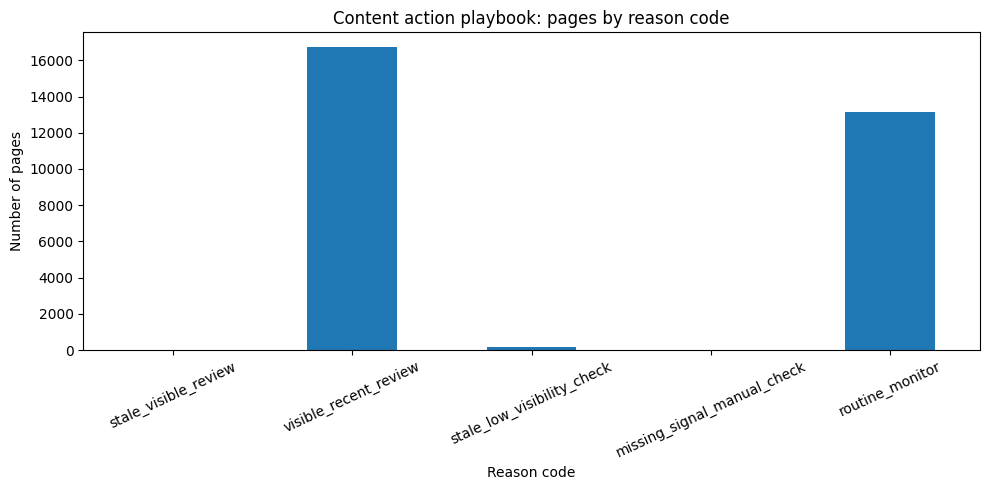

,freshness_bucket,n,observed_decline_pct
0,0–30 days,20480,51.137695
1,31–90 days,175,58.857143
2,91–180 days,9171,61.105659
3,181+ days,174,47.126437


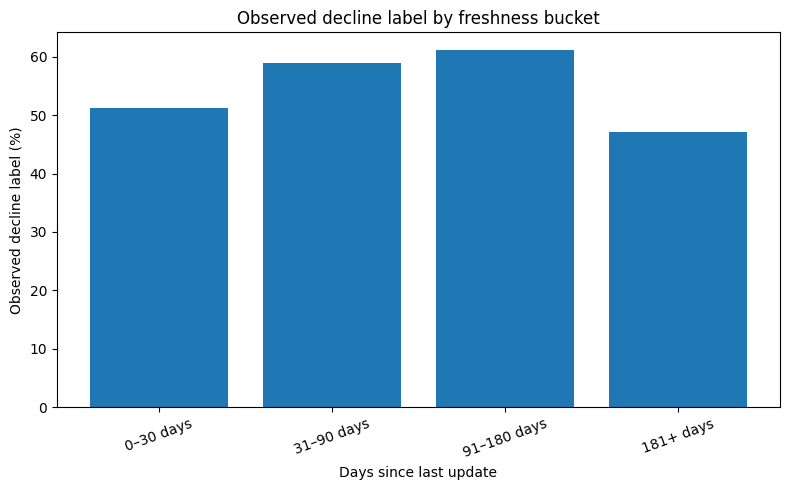


Exported files:
Queue CSV (generated; keep out of Git): /content/flyrank-ml-internship/work/outputs/content_action_playbook_queue.csv
Metrics receipt (safe to review and commit): /content/flyrank-ml-internship/work/outputs/action_playbook_metrics.json
Reason-code figure (safe to review and commit): /content/flyrank-ml-internship/work/figures/action_playbook_reason_codes.png
Freshness figure written: True; path: /content/flyrank-ml-internship/work/figures/observed_decay_refresh_insight.png
No client names, domains, URLs, private queries, or raw page text are exported.


In [5]:
# Export the ranked queue, monitoring receipt, and reusable figures.
import matplotlib.pyplot as plt

outputs_dir = repo_root / "work" / "outputs"
figures_dir = repo_root / "work" / "figures"
outputs_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

queue_path = outputs_dir / "content_action_playbook_queue.csv"
receipt_path = outputs_dir / "action_playbook_metrics.json"
reason_fig_path = figures_dir / "action_playbook_reason_codes.png"
decay_fig_path = figures_dir / "observed_decay_refresh_insight.png"

# CSV is regenerated locally; repository rules may intentionally keep it out of Git.
queue_export.to_csv(queue_path, index=False)
with open(receipt_path, "w", encoding="utf-8") as f:
    json.dump(monitoring_receipt, f, indent=2)

# Figure 1: how much of the dataset falls into each action reason code.
reason_counts = queue["reason_code"].value_counts().reindex(
    ["stale_visible_review", "visible_recent_review", "stale_low_visibility_check",
     "missing_signal_manual_check", "routine_monitor"],
    fill_value=0,
)
fig, ax = plt.subplots(figsize=(10, 5))
reason_counts.plot(kind="bar", ax=ax)
ax.set_title("Content action playbook: pages by reason code")
ax.set_xlabel("Reason code")
ax.set_ylabel("Number of pages")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(reason_fig_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Figure 2: descriptive decline rates by freshness bucket, when the label is available.
# This is a descriptive audit only; the label never enters the queue ranking.
decay_fig_written = False
if "trend_direction" in df.columns:
    label_frame = df[["days_since_last_update", "trend_direction"]].copy()
    label_frame["observed_decline"] = label_frame["trend_direction"].eq("down")
    label_frame["freshness_bucket"] = pd.cut(
        label_frame["days_since_last_update"],
        bins=[-np.inf, 30, 90, 180, np.inf],
        labels=["0–30 days", "31–90 days", "91–180 days", "181+ days"],
        right=True,
    )
    decay_summary = (
        label_frame.dropna(subset=["freshness_bucket"])
        .groupby("freshness_bucket", observed=False)
        .agg(n=("observed_decline", "size"), observed_decline_rate=("observed_decline", "mean"))
        .reset_index()
    )
    decay_summary["observed_decline_pct"] = decay_summary["observed_decline_rate"] * 100
    display(decay_summary[["freshness_bucket", "n", "observed_decline_pct"]])
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.bar(decay_summary["freshness_bucket"].astype(str), decay_summary["observed_decline_pct"])
    ax.set_title("Observed decline label by freshness bucket")
    ax.set_xlabel("Days since last update")
    ax.set_ylabel("Observed decline label (%)")
    ax.tick_params(axis="x", rotation=20)
    fig.tight_layout()
    fig.savefig(decay_fig_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    decay_fig_written = True
else:
    print("trend_direction is unavailable; skipped the descriptive freshness figure.")

print("\nExported files:")
print(f"Queue CSV (generated; keep out of Git): {queue_path}")
print(f"Metrics receipt (safe to review and commit): {receipt_path}")
print(f"Reason-code figure (safe to review and commit): {reason_fig_path}")
print(f"Freshness figure written: {decay_fig_written}; path: {decay_fig_path}")
print("No client names, domains, URLs, private queries, or raw page text are exported.")


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.